# Nondeterministic Actions: Solving Tic-Tac-Toe with AND-OR-Tree Search

## Introduction 
 
Multiplayer games can be implemented as:
1. __Nondeterministic actions:__ The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)).

We will implement
* __AND-OR-Tree search.__

Each action consists of the move by the player (OR levels in the tree) and all possible (i.e., nondeterministic) responses by the opponents (AND levels). The action therefore results in a set of possible states.

We will search for a __conditional plan__ using AND-OR-Tree search. 

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

In [ ]:
# Hàm phụ: cho tác tử đấu random_player 100 ván khi đi trước (x) và 100 ván khi đi sau (o), đo thời gian mỗi nước
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tictactoe import other
np.random.seed(0)

def danh_gia(agent, ten, N = 100):
    dong = []
    for vai in 'xo':
        t = []
        def dem(board, player = 'x'):
            s = time.perf_counter(); a = agent(board, player); t.append(time.perf_counter() - s); return a
        r = play(dem, random_player, N) if vai == 'x' else play(random_player, dem, N)
        dong.append([ten, 'đi trước' if vai == 'x' else 'đi sau', r[vai], r['d'], r[other(vai)], round(1000 * np.mean(t), 1)])
    return pd.DataFrame(dong, columns = ['Tác tử', 'Vai', 'Thắng', 'Hòa', 'Thua', 'ms/nước'])

def ve(bang, tieu_de):
    nhan = bang['Tác tử'] + ' (' + bang['Vai'] + ')'
    ax = bang[['Thắng', 'Hòa', 'Thua']].set_index(nhan).plot.barh(stacked = True, color = ['#2a78d6', '#c3c2b7', '#eb6834'], figsize = (8, 0.45 * len(bang) + 1.3))
    ax.set_xlabel('số ván'); ax.set_ylabel(''); ax.set_title(tieu_de); ax.invert_yaxis()
    ax.legend(ncol = 3, loc = 'upper center', bbox_to_anchor = (0.5, -0.2))
    plt.show()

In [ ]:
# Bốn trạng thái kiểm thử (đến lượt x đi)
def ban(x = (), o = ()):
    b = empty_board()
    for i in x: b[i] = 'x'
    for i in o: b[i] = 'o'
    return b

tests = {'A: x sắp thắng': ban((0, 4), (1, 3)), 'B: x phải đi ô 7': ban((0, 2), (1, 4)),
         'C: bất lợi': ban((2,), (0, 8)), 'D: bàn rỗng': ban()}

## Solving Tic-Tac-Toe using AND-OR-Tree Search

The opponent can be modeled as part of the environment. The opponent's action as a response to the agent's 
action makes the environment appear non-deterministic (see AIMA page 125 or the slides). The ADS-OR-Tree algorithm uses the following functions:

* `is_goal(state)`: determine if the current board/state has a winner.
* `is_cycle(path)`: determine if we are in a loop (the tic-tac-toe problem has no loops so I do not implement it).
* `results(state, action)`: returns all states following state + action.


### Cycles

The path is typically used for loop checking. We ignore it here since tic-tac-toe does not have cycles.

### Goals

Reaching the goal means that the agent has successfully finished the task. 

For games, `terminal(s)` checks if `s` is a terminal state, but a terminal state can also indicate that 
the player lost (which indicates a failure). This can determined by the 
`utility(s)` function. Tic-tac-toe also has draws and we need to decide if a draw is considered successfully reaching
the goal or a failure.

### Non-deterministic Results

Since the opponent and her moves are part of the environment, `results()` returns for a state $\times$ action combination a set of new states that reflects all possible responses by the opponent.

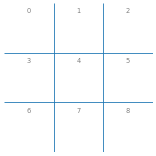


Set of possible state for placing an x at position 4 of an empty board and the opponent's move:


[['o', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', 'o', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', 'o', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', 'o', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', 'o', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', 'o', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', 'o', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', 'o']]

In [5]:
def results(state, action, player = 'x'):
    """produce the set of states after the provided action for player. 
       It is the set of boards with the action and all possible reactions by the opponent."""
    
    opponent = other(player)
    state = state.copy()
    
    # player's move
    state[action] = player
    
    # opponent reacts
    r = list()
    o_actions = actions(state)
    
    # board is full
    if len(o_actions) < 1 : return [state]
    
    for o_a in o_actions:
        s = state.copy()
        s[o_a] = opponent
        r.append(s)    
    
    return r

show_board(empty_board())

print()
print("Set of possible state for placing an x at position 4 of an empty board and the opponent's move:")
results(empty_board(), 4)

### Recursive AND-OR Search (DFS)

In [6]:
# define global variables for debugging
DEBUG = 1
COUNT = 0 # used to report the number of searched nodes

def and_or_search(state, player = 'x', draw_is_win = True):
    """start the search. Consider draw_is_win a goal state?"""
    global DEBUG, COUNT
    COUNT = 0
    
    plan = or_search(state, player, draw_is_win)
    
    if DEBUG >= 1: 
        print(f"Number of nodes searched: {COUNT}")  
    
    return plan
 

def or_search(state, player, draw_is_win):
    """Or step of the search: the player makes a move. 
    We try all possible action and return a conditional 
    plan for the first action that only has goal states as leaf nodes. 
    If none can be found, then failure (None) is returned.
    
    Note: path is not used in this implementation since tic-tac-toe does not 
    need cycle checking.
    """
    global DEBUG, COUNT
    COUNT += 1
    
    # goal check
    u = utility(state, player)
    if u == -1 or (not draw_is_win and u == 0): return None # failure
     
    # cycles check: tic-tac-toe has no cycles

    # check all possible actions
    for action in actions(state):
        plan = and_search(results(state, action, player), player, draw_is_win)
        if plan is not None: 
            return [action, plan]
    
    # failure
    return None


def and_search(states, player, draw_is_win):
    """And step of the search: Represents all opponent's possible moves. 
    Follow all possible states (call the or step). 
    Return a conditional plan only if all paths lead to a goal state."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return plans only if no state fails
    plans = []
    for s in states:
        # goal check
        u = utility(s, player)
        if u == 1: return "win"  # success
        if draw_is_win and u == 0: return "draw"

        plan = or_search(s, player, draw_is_win)
        
        if plan is None: 
            return None    # found a state that fails so we abandon this subtree!
        plans.append(['if', s, 'then', plan])
        
    return plans

And-or search looks for a subtree (i.e., an action) that guarantees a win and returns a conditional plan for this subtree. If no such subtree exists, no plan is returned. The algorithm only searches a fraction of the game tree since it abandons the current subtree when it finds the first leaf node that is not a win (see `and_search` function).

# Some Tests

## x is about to win

Board:


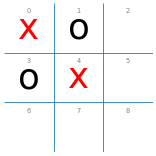


Win or draw:
Number of nodes searched: 22


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'],
   'then',
   [5,
    [['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]]]]

CPU times: total: 0 ns
Wall time: 8.03 ms


In [7]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

Why does it play 2 and not 8!!!

In [8]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 30


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '], 'then', [8, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'], 'then', [6, 'win']]]]

CPU times: total: 15.6 ms
Wall time: 7.55 ms


## x can draw_is_win if it chooses 7

Board:


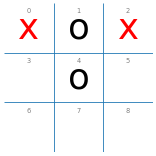


Win or draw:
Number of nodes searched: 64


[7,
 [['if',
   ['x', 'o', 'x', 'o', 'o', ' ', ' ', 'x', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'o', 'x', 'o', 'x', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'o', 'x', ' ', 'x', 'o'],
      'then',
      [6, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', 'o', ' ', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', 'o', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', ' ', 'o', 'x', 'o'],
      'then',
      [5, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', ' ', 'x', 'o'],
   'then',
   [3,
    [['if', ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'], 'then', [6, 'win']],
     ['if',
      ['x', '

CPU times: total: 15.6 ms
Wall time: 9.52 ms


In [9]:

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
#board[3] = 'o'
board[4] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [10]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 69


None

CPU times: total: 0 ns
Wall time: 4.52 ms


## a bad situation

Board:

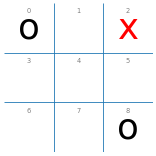


Win or draw:
Number of nodes searched: 155


None

CPU times: total: 15.6 ms
Wall time: 10.5 ms


In [11]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

## Empty board: Only a draw_is_win can be guaranteed

Board:


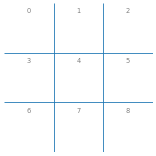


Win or draw:


[0,
 [['if',
   ['x', 'o', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
   'then',
   [2,
    [['if',
      ['x', 'o', 'x', 'o', ' ', ' ', ' ', ' ', ' '],
      'then',
      [4,
       [['if',
         ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '],
         'then',
         [6, 'win']],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
            'then',
            [7, 'draw']]]]],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
            'then',
            [6, 'win']]]]],
        ['if',
        

CPU times: total: 46.9 ms
Wall time: 58.3 ms


In [19]:
board = empty_board() 

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [13]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:


Number of nodes searched: 16213


None

CPU times: total: 750 ms
Wall time: 844 ms


## Experiments

### And-Or Tree Search vs. Random

Put AND-OR search into a wrapper agent function. Note that if AND-OR search cannot guarantee a win then
it does not return a plan, nut `None`. In this case, we do not know what the best (i.e., the least "bad") 
move is, so I make the agent play randomly. Other methods that we will learn about later can determine the utility of a move, even if it does not guarantee a win.

In [14]:
DEBUG = 0

def and_or_player(board, player = 'x'):
    plan = and_or_search(board, player)

    # if there is no plan then we do a random action
    if plan is None: 
        return np.random.choice(actions(board))
    else:
        return plan[0]


print("and-or-search vs. random:")
%time display(play(and_or_player, random_player))

print()
print("random vs. and-or-search")
%time display(play(random_player, and_or_player))

and-or-search vs. random:


{'x': 95, 'o': 0, 'd': 5}

CPU times: total: 4.48 s
Wall time: 4.64 s

random vs. and-or-search


{'x': 0, 'o': 68, 'd': 32}

CPU times: total: 5.67 s
Wall time: 5.94 s


**Note how slow this is!**

My lazy implementation is a _simple reflex agent_ that recreates a conditional plan every time it is asked for an action. ut since And-Or search already produces a complete conditional plan for the empty board, a better implementation would use a _model-based reflex agent_ that store this precomputed plan and just follow it without more planing.

### And-Or Tree Search vs. And-Or Tree Search

In [15]:
# No randomness -> run only once

%time display(play(and_or_player, and_or_player, N = 1))

{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 109 ms
Wall time: 82.2 ms


In [16]:
# Nước đi và số nút của AND-OR search trên bốn trạng thái
DEBUG = 0
dong = []
for ten, b in tests.items():
    plan = and_or_search(b, 'x')
    dong.append([ten, plan[0] if plan else 'không có kế hoạch', COUNT])
bang = pd.DataFrame(dong, columns = ['Trạng thái', 'Nước đi', 'Số nút'])
display(bang)

,Trạng thái,Nước đi,Số nút
0,A: x sắp thắng,2,22
1,B: x phải đi ô 7,7,64
2,C: bất lợi,không có kế hoạch,155
3,D: bàn rỗng,0,966


**Nhận xét:**
- **A (x sắp thắng):** chọn ô 2 chứ không phải ô 8. Đặt x vào ô 2 tạo hai mối đe dọa cùng lúc (ô 6 và ô 8) nên mọi phản ứng của o đều dẫn đến thắng; AND-OR chọn nước đầu tiên có kế hoạch như vậy chứ không tìm đường thắng ngắn nhất (22 nút).
- **B:** chọn ô 7 để chặn o; kế hoạch chỉ đảm bảo hòa (64 nút).
- **C (bất lợi):** không có kế hoạch nào (thế thua nếu o chơi đúng), phải xét hết 155 nút.
- **D (bàn rỗng):** chọn ô 0, kế hoạch đảm bảo hòa chứ không ép thắng được (966 nút).

,Tác tử,Vai,Thắng,Hòa,Thua,ms/nước
0,AND-OR,đi trước,97,3,0,11.1
1,AND-OR,đi sau,80,20,0,16.9


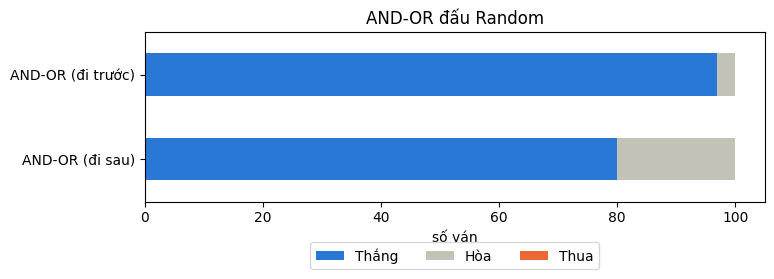

In [17]:
# AND-OR đấu Random
bang = danh_gia(and_or_player, 'AND-OR')
display(bang)
ve(bang, 'AND-OR đấu Random')

**Nhận xét:** AND-OR không thua ván nào trước Random: đi trước thắng 97, hòa 3; đi sau thắng 80, hòa 20. Mục tiêu của thuật toán là "thắng hoặc hòa" nên không bao giờ thua; mỗi nước mất khoảng 20–30 ms.